# Method Ablations

We seek Foundation Models properties to see why the compression methods work.

## Ablation 1: Zero-order empirical entropy

## Ablation 2: Blockwise heterogeneity

Compare the clusters induced by exponent-distribution JS distance with the architecture exposed through module types and normalized parameter names. The compression control preserves the JS cluster-size distribution when constructing the random partition.

Running architecture-vs-JS ablation for ResNet-18...


Running architecture-vs-JS ablation for BERT Base Uncased...


,model,tensors,architecture_signatures,module_type_groups,repeated_block_groups,js_clusters,js_threshold,js_clustering_seconds,adjusted_rand_index,normalized_mutual_information,js_cluster_purity,signature_concentration,element_weighted_js_cluster_purity,element_weighted_signature_concentration,same_signature_mean_js,different_signature_mean_js,same_signature_same_cluster_fraction,different_signature_same_cluster_fraction
0,ResNet-18,62,38,5,4,44,0.05,0.1053,0.0940,0.8758,0.7581,0.6613,0.6358,0.6118,0.2689,0.6429,0.1250,0.0155
1,BERT Base Uncased,199,23,5,1,111,0.05,0.5714,0.4032,0.7651,0.8090,0.4874,0.6067,0.9452,0.1014,0.5289,0.3854,0.0227


,model,strategy,repeats,clusters,full_model_ratio_pct,exponent_ratio_pct,setup_seconds,encode_seconds,total_compression_seconds,encode_iqr_seconds,codebook_bytes,roundtrip_ok
0,ResNet-18,ZipNN local,5,0,66.8424,33.5821,0.0000,0.1154,0.1154,0.0010,0,True
1,ResNet-18,Global shared,5,1,67.4712,34.8345,0.1480,0.1060,0.2597,0.0038,354,True
2,ResNet-18,Module type,5,5,67.1041,34.0944,0.1526,0.1048,0.2575,0.0005,2177,True
3,ResNet-18,Architecture signature,5,38,66.8151,33.5151,0.1901,0.0986,0.2877,0.0013,7724,True
4,ResNet-18,Random matched to JS,5,44,66.9351,33.7623,0.1871,0.0967,0.2847,0.0023,8496,True
5,ResNet-18,JS distance,5,44,66.7581,33.4082,0.1845,0.0942,0.2786,0.0006,7080,True
6,BERT Base Uncased,ZipNN local,5,0,66.3849,32.7611,0.0000,1.3151,1.3151,0.0012,0,True
7,BERT Base Uncased,Global shared,5,1,66.5021,32.9690,0.3792,1.9180,2.2987,0.0033,708,True
8,BERT Base Uncased,Module type,5,5,66.4797,32.9256,0.4962,1.1932,1.6896,0.0101,2538,True
9,BERT Base Uncased,Architecture signature,5,23,66.3256,32.6336,0.9961,1.1397,2.1311,0.0042,10409,True


,model,module_path,repeated_blocks,block_type,child_modules
0,ResNet-18,layer1,2,BasicBlock,layer1.0 | layer1.1
1,ResNet-18,layer2,2,BasicBlock,layer2.0 | layer2.1
2,ResNet-18,layer3,2,BasicBlock,layer3.0 | layer3.1
3,ResNet-18,layer4,2,BasicBlock,layer4.0 | layer4.1
4,BERT Base Uncased,encoder.layer,12,BertLayer,encoder.layer.0 | encoder.layer.1 | encoder.la...


,model,architecture_signature,module_type,tensors,js_clusters,modal_cluster_fraction
0,ResNet-18,layer4.#.conv2.weight,Conv2d,2,2,0.5000
1,ResNet-18,layer4.#.conv1.weight,Conv2d,2,2,0.5000
2,ResNet-18,layer3.#.conv2.weight,Conv2d,2,2,0.5000
3,ResNet-18,layer3.#.conv1.weight,Conv2d,2,2,0.5000
4,ResNet-18,fc.weight,Linear,1,1,1.0000
5,ResNet-18,layer2.#.conv2.weight,Conv2d,2,1,1.0000
6,ResNet-18,layer2.#.conv1.weight,Conv2d,2,2,0.5000
7,ResNet-18,layer4.#.downsample.0.weight,Conv2d,1,1,1.0000
8,ResNet-18,layer1.#.conv1.weight,Conv2d,2,2,0.5000
9,ResNet-18,layer1.#.conv2.weight,Conv2d,2,1,1.0000


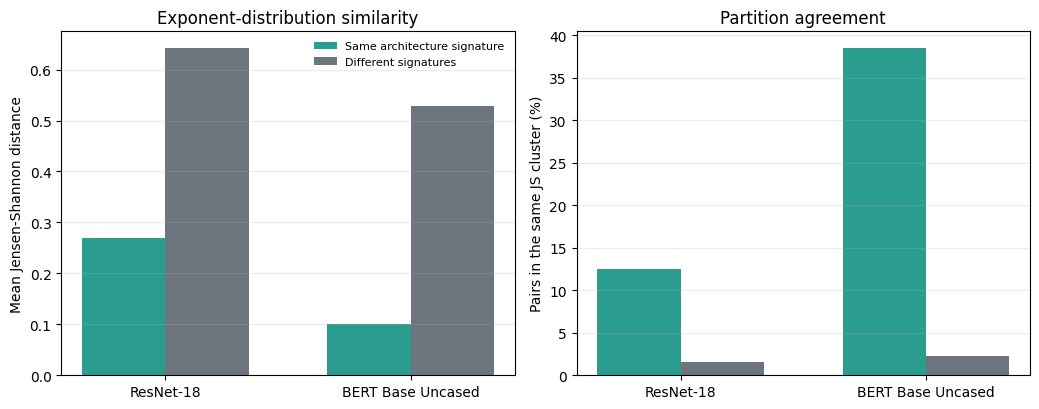

In [1]:
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", message="IProgress not found.*")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torchvision.models import ResNet18_Weights, resnet18
from transformers import AutoModel, logging as transformers_logging

from neuralzip.ablations import cluster_structure_ablation

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
output_dir = root / "examples" / "outputs" / "ablations"
output_dir.mkdir(parents=True, exist_ok=True)

alignment_models = {
    "ResNet-18": resnet18(weights=ResNet18_Weights.DEFAULT).to(torch.bfloat16).eval(),
    "BERT Base Uncased": AutoModel.from_pretrained(
        "google-bert/bert-base-uncased", dtype=torch.bfloat16
    ).eval(),
}

alignment_outputs = {}
tables = {
    name: []
    for name in (
        "summary",
        "pair_summary",
        "signature_summary",
        "cluster_summary",
        "repeated_block_summary",
        "assignments",
        "compression_runs",
        "compression_summary",
    )
}
for model_name, model in alignment_models.items():
    print(f"Running architecture-vs-JS ablation for {model_name}...", flush=True)
    result = cluster_structure_ablation(
        model,
        cluster_js_threshold=0.05,
        repeats=5,
        random_seed=2026,
    )
    alignment_outputs[model_name] = result
    for table_name in tables:
        table = result[table_name].copy()
        table.insert(0, "model", model_name)
        tables[table_name].append(table)

for table_name, model_tables in tables.items():
    tables[table_name] = pd.concat(model_tables, ignore_index=True)
    tables[table_name].to_csv(
        output_dir / f"architecture_js_{table_name}.csv", index=False
    )

display(tables["summary"].round(4))
display(tables["compression_summary"].round(4))
display(tables["repeated_block_summary"])
display(
    tables["signature_summary"][
        [
            "model",
            "architecture_signature",
            "module_type",
            "tensors",
            "js_clusters",
            "modal_cluster_fraction",
        ]
    ].groupby("model", group_keys=False).head(20).round(4)
)

pair_plot = tables["pair_summary"].copy()
pair_plot["group"] = np.where(
    pair_plot["same_signature"], "Same architecture signature", "Different signatures"
)
models_order = list(alignment_models)
groups_order = ["Same architecture signature", "Different signatures"]
x = np.arange(len(models_order))
width = 0.34
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
colors = ["#2A9D8F", "#6C757D"]
for offset, (group, color) in enumerate(zip(groups_order, colors)):
    subset = pair_plot[pair_plot["group"] == group].set_index("model")
    positions = x + (offset - 0.5) * width
    axes[0].bar(positions, subset.loc[models_order, "mean_js"], width, label=group, color=color)
    axes[1].bar(
        positions,
        100 * subset.loc[models_order, "same_js_cluster_fraction"],
        width,
        label=group,
        color=color,
    )
axes[0].set_ylabel("Mean Jensen-Shannon distance")
axes[0].set_title("Exponent-distribution similarity")
axes[1].set_ylabel("Pairs in the same JS cluster (%)")
axes[1].set_title("Partition agreement")
for axis in axes:
    axis.set_xticks(x, models_order)
    axis.grid(axis="y", alpha=0.25)
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(output_dir / "architecture_vs_js_alignment.pdf", bbox_inches="tight")
display(fig)
plt.close(fig)


## Ablation 3: Packed exponents entropy

## Ablation 4: First-order exponent entropy

Compare zero-order entropy with the conditional entropy obtained when the previous exponent is used as context.

,model,tensors,exponent_symbols,transitions,h0_bits_per_exponent,h1_bits_per_exponent,entropy_reduction_bits_per_exponent,entropy_reduction_pct
0,ResNet-18,62,11689512,11689450,2.7449,2.6042,0.1407,5.1248
1,BERT Base Uncased,199,109482240,109482041,2.5984,2.5932,0.0052,0.2019


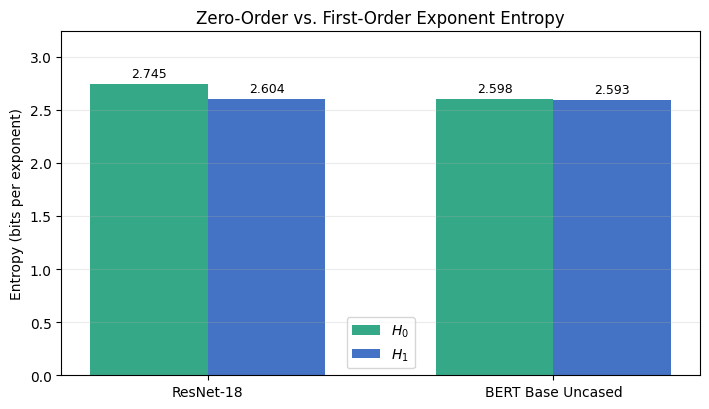

In [2]:
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", message="IProgress not found.*")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torchvision.models import ResNet18_Weights, resnet18
from transformers import AutoModel, logging as transformers_logging

from neuralzip.ablations import exponent_order_entropies

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

root = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
output_dir = root / "examples" / "outputs" / "ablations"
output_dir.mkdir(parents=True, exist_ok=True)

models = {
    "ResNet-18": resnet18(weights=ResNet18_Weights.DEFAULT).to(torch.bfloat16).eval(),
    "BERT Base Uncased": AutoModel.from_pretrained(
        "google-bert/bert-base-uncased", dtype=torch.bfloat16
    ).eval(),
}
order_entropy = pd.DataFrame(
    [{"model": name, **exponent_order_entropies(model)} for name, model in models.items()]
)
order_entropy.to_csv(output_dir / "order_0_vs_order_1_entropy.csv", index=False)
display(order_entropy.round(4))

x = np.arange(len(order_entropy))
width = 0.34
fig, ax = plt.subplots(figsize=(7.2, 4.2))
bars_h0 = ax.bar(
    x - width / 2, order_entropy["h0_bits_per_exponent"], width, label=r"$H_0$", color="#35A987"
)
bars_h1 = ax.bar(
    x + width / 2, order_entropy["h1_bits_per_exponent"], width, label=r"$H_1$", color="#4472C4"
)
ax.bar_label(bars_h0, fmt="%.3f", padding=3, fontsize=9)
ax.bar_label(bars_h1, fmt="%.3f", padding=3, fontsize=9)
ax.set_xticks(x, order_entropy["model"])
ax.set_ylabel("Entropy (bits per exponent)")
ax.set_title("Zero-Order vs. First-Order Exponent Entropy")
ax.grid(axis="y", alpha=0.25)
ax.legend()
ax.set_ylim(0, max(order_entropy["h0_bits_per_exponent"]) * 1.18)
fig.tight_layout()
fig.savefig(output_dir / "order_0_vs_order_1_entropy.pdf", bbox_inches="tight")
display(fig)
plt.close(fig)


## Ablation 5: Fast and ratio components

Isolate shared-codebook acceleration from packed-exponent compression and compare both components with ZipNN and the complete NeuralZip method.

In [3]:
from neuralzip.ablations import neuralzip_component_ablation

component_runs = []
component_summaries = []
for model_name, model in models.items():
    print(f"Running component ablation for {model_name}...", flush=True)
    runs, summary = neuralzip_component_ablation(
        model,
        repeats=5,
        cluster_js_threshold=0.05,
        n_values=(2, 3, 4),
        layout="original",
        chunk_size=256 << 10,
        compression_threshold=0.95,
        packed_time_budget_ratio=0.10,
    )
    runs.insert(0, "model", model_name)
    summary.insert(0, "model", model_name)
    component_runs.append(runs)
    component_summaries.append(summary)

component_runs = pd.concat(component_runs, ignore_index=True)
component_ablation = pd.concat(component_summaries, ignore_index=True)
for model_name, indices in component_ablation.groupby("model").groups.items():
    group = component_ablation.loc[indices]
    baseline = group[group["variant"] == "ZipNN"].iloc[0]
    component_ablation.loc[indices, "compression_gain_pp_vs_zipnn"] = (
        baseline["compression_pct"] - group["compression_pct"]
    )
    component_ablation.loc[indices, "compression_speedup_vs_zipnn"] = (
        baseline["compression_seconds"] / group["compression_seconds"]
    )

component_runs.to_csv(output_dir / "component_ablation_runs.csv", index=False)
component_ablation.to_csv(output_dir / "component_ablation_summary.csv", index=False)
display(
    component_ablation[[
        "model",
        "variant",
        "compression_pct",
        "compression_seconds",
        "compression_gain_pp_vs_zipnn",
        "compression_speedup_vs_zipnn",
    ]].round(4)
)


Running component ablation for ResNet-18...


Running component ablation for BERT Base Uncased...


,model,variant,compression_pct,compression_seconds,compression_gain_pp_vs_zipnn,compression_speedup_vs_zipnn
0,ResNet-18,ZipNN,33.4599,0.0905,0.0000,1.0000
1,ResNet-18,Fast only,33.3934,0.0839,0.0665,1.0787
2,ResNet-18,Ratio only,32.5812,0.7385,0.8787,0.1225
3,ResNet-18,NeuralZip,32.3673,0.0896,1.0926,1.0095
4,BERT Base Uncased,ZipNN,32.6574,0.9297,0.0000,1.0000
5,BERT Base Uncased,Fast only,32.6437,0.8631,0.0137,1.0772
6,BERT Base Uncased,Ratio only,32.6378,7.0385,0.0196,0.1321
7,BERT Base Uncased,NeuralZip,32.6411,0.8581,0.0163,1.0834
